# Preprocessing Audio Extraction Check

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from woofdata.path import data_path, load_data_dir_from_env_file
from woofdecoder.preprocess.media import (
    TARGET_SAMPLE_RATE,
    describe_media,
    load_audio_16k,
    sample_frames,
)

In [3]:
load_data_dir_from_env_file()

VIDEO_PATH = data_path("test/media_test.mp4")
SEGMENT_START_S = 1.0
SEGMENT_END_S = 4.0

info = describe_media(VIDEO_PATH)
print()
audio = load_audio_16k(VIDEO_PATH)
print()
frames, frame_times = sample_frames(VIDEO_PATH, SEGMENT_START_S, SEGMENT_END_S)


File: media_test.mp4
Length: 5.46 s
Audio
44,100 Hz
2 channel(s)
Video
30.0 fps
1080 , 1920

Loading audio from media_test.mp4
Read 240,640 samples, 2 channels, 44,100 Hz
Converted to mono 16,000 Hz: 87,307, samples = 5.46 s

Sample 4 frames from 1.000-4.000 s
Frame times: [1.375, 2.125, 2.875, 3.625]
Frame 1/4 at 1.375 s: (1920, 1080, 3)
Frame 2/4 at 2.125 s: (1920, 1080, 3)
Frame 3/4 at 2.875 s: (1920, 1080, 3)
Frame 4/4 at 3.625 s: (1920, 1080, 3)


## Audio, the waveform with segment shaded

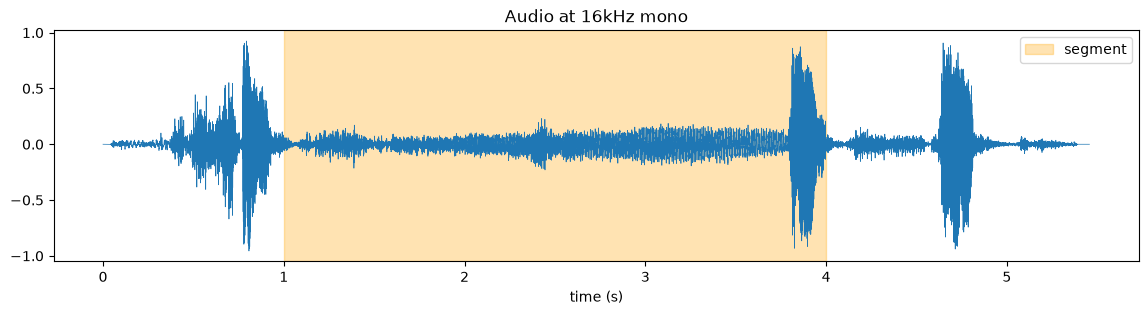

In [4]:
if audio is not None:
    seconds = np.arange(len(audio)) / TARGET_SAMPLE_RATE
    plt.figure(figsize=(14, 3))
    plt.plot(seconds, audio, linewidth=0.5)
    plt.axvspan(SEGMENT_START_S, SEGMENT_END_S, color="orange", alpha=0.3, label="segment")
    plt.xlabel("time (s)")
    plt.title("Audio at 16kHz mono")
    plt.legend()
    plt.show()

## Video, the frames taken from the segment

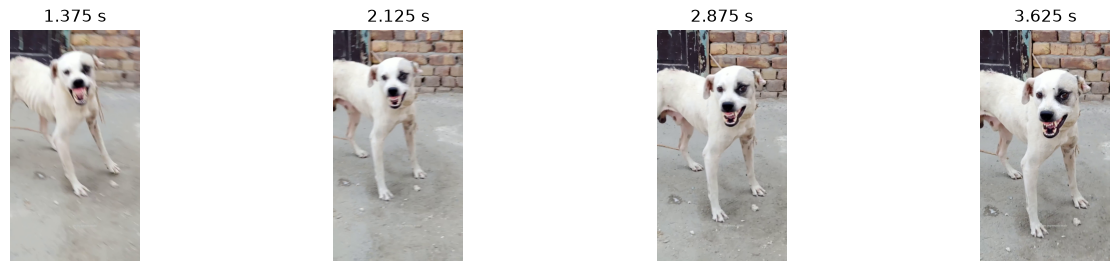

In [5]:
if frames:
    figure, axes = plt.subplots(1, len(frames), figsize=(4*len(frames),3))
    for axis, frame, time_s in zip(np.atleast_1d(axes), frames, frame_times):
        axis.imshow(frame)
        axis.set_title(f"{time_s:.3f} s")
        axis.axis("off")
    plt.show()